In [ ]:
# Python 3.5
import sys
assert sys.version_info >= (3, 5)

# sklearn
import sklearn
assert sklearn.__version__ >= "0.20"

# other imports
import numpy as np
import pandas as pd
import os

# allow google drive access
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Get Excel Data Using Pandas

In [ ]:
file = '/content/drive/MyDrive/Colab Notebooks/hw3/extra_credits_dataset.xlsx'
df = pd.read_excel(file)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 904 entries, 0 to 903
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Extra   503 non-null    float64
 1   Total   904 non-null    float64
dtypes: float64(2)
memory usage: 14.3 KB


# Get mean, min, and max and all students who reported EC

In [ ]:
df.describe()

,Extra,Total
count,503.000000,904.000000
mean,0.797654,80.822806
std,0.732681,19.559834
min,0.100000,0.000000
25%,0.300000,75.708748
50%,0.600000,86.111765
75%,1.100000,92.869629
max,5.000000,106.754098


# Percentage of EC Students who reported no more than 1 point of EC

In [ ]:
# gets all students who reported less than 1 point
students_less_than_1 = (df['Extra']<1).sum()

# drops all students who didn't report extra credit
EC_students = len(df['Extra'].dropna())

percentage = students_less_than_1 / EC_students * 100
print(percentage)


69.38369781312127


# Correlation Coefficient

In [ ]:
corrcoef = df.corr()
print(corrcoef)

          Extra     Total
Extra  1.000000  0.187061
Total  0.187061  1.000000


# Scatter Plot

<Axes: xlabel='Extra', ylabel='Total'>

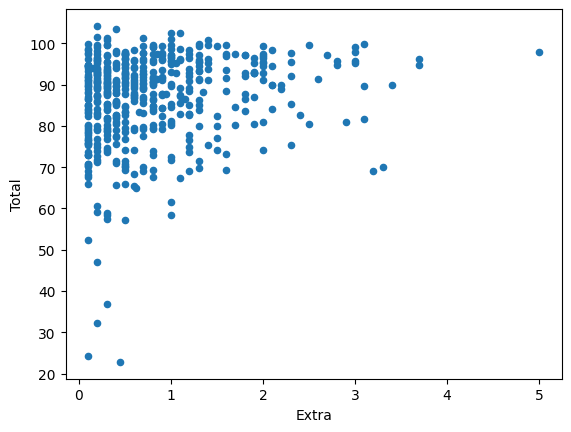

In [ ]:
df.plot.scatter(x='Extra', y='Total')

# Prepare data for Linear Regression

In [ ]:
clean_df = df.dropna()

# Train ML Model

In [ ]:
# linear regression model
from sklearn.linear_model import LinearRegression

extra = clean_df[['Extra']]
total = clean_df['Total']

lin_reg = LinearRegression()
lin_reg.fit(extra, total)

slope = lin_reg.coef_[0]
y_intercept = lin_reg.intercept_

print(f"y = {slope:.2f}x + {y_intercept:.2f}")

y = 2.79x + 84.54


# Get RMSE

In [ ]:
from sklearn.metrics import mean_squared_error

y_pred = lin_reg.predict(extra)
rmse = np.sqrt(mean_squared_error(total, y_pred))
print(rmse)

10.711492451359439


# Graph

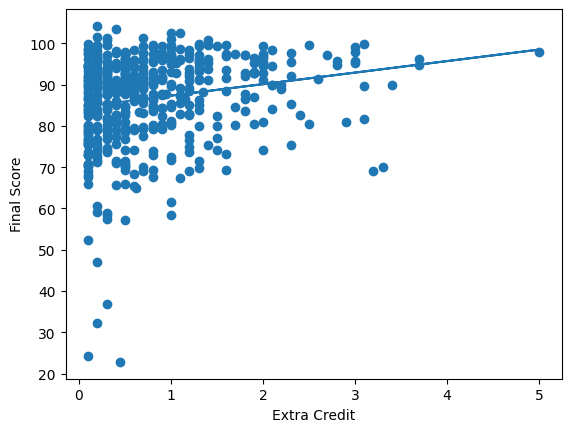

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(clean_df['Extra'], clean_df['Total'])
plt.plot(clean_df['Extra'], y_pred)
plt.xlabel("Extra Credit")
plt.ylabel("Final Score")
plt.show()